In [2]:
# Cau hinh: MODE='full' de chay IMDb day du; MODE='smoke' de kiem tra nhanh.
import os
os.environ.setdefault('CUBLAS_WORKSPACE_CONFIG', ':4096:8')
from pathlib import Path
from collections import Counter
from functools import partial
import copy
import gc
import hashlib
import html
import json
import math
import random
import re
import shutil
import time
import urllib.request

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.nn.utils.rnn import pack_padded_sequence
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, ConfusionMatrixDisplay)
from IPython.display import display

BASE = Path.cwd().resolve()
if not (BASE / 'transformer_block.py').is_file():
    BASE = BASE / 'lab07'
if not (BASE / 'transformer_block.py').is_file():
    raise FileNotFoundError('Mo notebook tu thu muc NLP/ hoac NLP/lab07/.')
if str(BASE) not in sys.path:
    sys.path.insert(0, str(BASE))
from positional_encoding import PositionalEncoding, positional_encoding
from transformer_block import TransformerBlock, MultiHeadSelfAttention

MODE = os.environ.get('LAB07_MODE', 'full')
if MODE not in {'full', 'smoke'}:
    raise ValueError('LAB07_MODE must be full or smoke')
CFG = dict(seed=42, d_model=128, d_ff=512, n_layers=1, dropout=0.1,
           n_heads=4, max_length=128, batch_size=64, epochs=6,
           learning_rate=1e-3, clip_grad_norm=1.0, max_vocab=20000)
if MODE == 'smoke':
    CFG.update(epochs=1, batch_size=16)
OUT = BASE if MODE == 'full' else BASE / 'outputs' / 'smoke'
OUT.mkdir(parents=True, exist_ok=True)
ARTIFACTS = OUT / 'outputs' if MODE == 'full' else OUT / 'artifacts'
ARTIFACTS.mkdir(parents=True, exist_ok=True)
CHECKPOINTS = ARTIFACTS / 'checkpoints'
CHECKPOINTS.mkdir(exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(min(4, os.cpu_count() or 1))

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True
    torch.use_deterministic_algorithms(True)

def synchronize():
    if DEVICE.type == 'cuda':
        torch.cuda.synchronize(DEVICE)

seed_everything(CFG['seed'])
RUNS, RESULT_ROWS = {}, []
(ARTIFACTS / 'configuration.json').write_text(
    json.dumps(dict(mode=MODE, device=str(DEVICE), torch=torch.__version__, **CFG), indent=2),
    encoding='utf-8')
print('Mode:', MODE, '| device:', DEVICE)
print(CFG)


Mode: full | device: cuda
{'seed': 42, 'd_model': 128, 'd_ff': 512, 'n_layers': 1, 'dropout': 0.1, 'n_heads': 4, 'max_length': 128, 'batch_size': 64, 'epochs': 6, 'learning_rate': 0.001, 'clip_grad_norm': 1.0, 'max_vocab': 20000}


,experiment,pair,text_a,text_b,positional_encoding,pooled_l2,aligned_token_max_abs
0,1,1,I love NLP,NLP love I,False,1.016124e-07,1.192093e-07
1,1,1,I love NLP,NLP love I,True,1.629418e-01,1.242210e+00
2,1,2,dog bites man,man bites dog,False,2.279127e-07,4.768372e-07
3,1,2,dog bites man,man bites dog,True,2.457960e-01,1.374738e+00


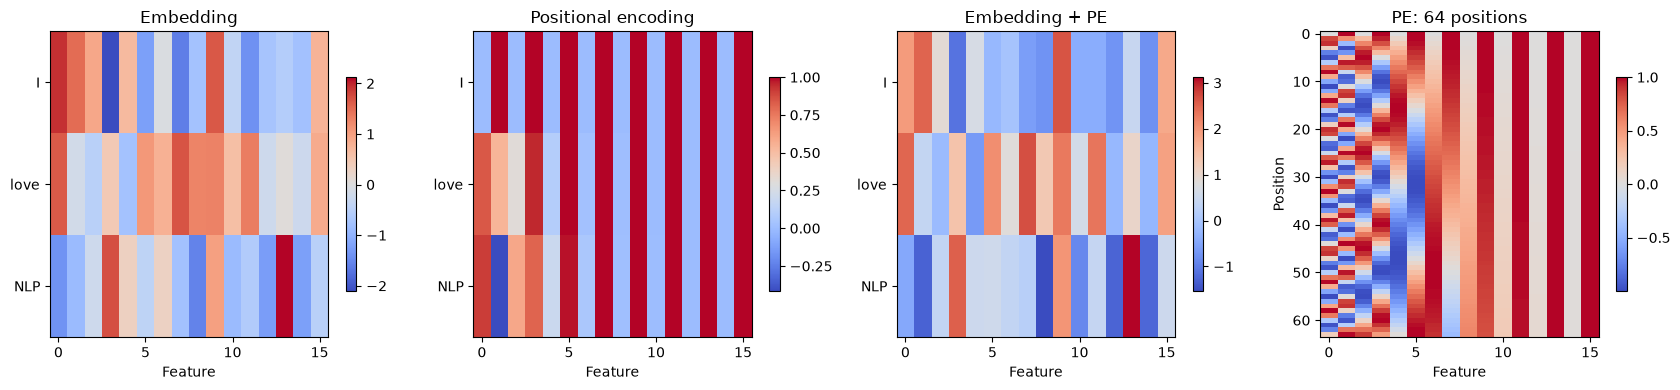

In [3]:
# 11. Experiment 1: embedding + PE; cac cap sequence hoan vi o muc 11-12.
seed_everything(CFG['seed'])
demo_words = ['I', 'love', 'NLP', 'dog', 'bites', 'man']
demo_vocab = {word: i for i, word in enumerate(demo_words)}
demo_embedding = nn.Embedding(len(demo_vocab), 16)
demo_block = TransformerBlock(16, 4, 64, dropout=0.0).eval()
demo_pe = PositionalEncoding(16, max_len=64)
demo_pairs = [('I love NLP', 'NLP love I'), ('dog bites man', 'man bites dog')]
permutation_rows = []
with torch.inference_mode():
    for pair_index, (first, second) in enumerate(demo_pairs, start=1):
        words_a, words_b = first.split(), second.split()
        ids = torch.tensor([[demo_vocab[w] for w in words_a],
                            [demo_vocab[w] for w in words_b]])
        embeddings = demo_embedding(ids)
        realign = torch.tensor([words_b.index(w) for w in words_a])
        for use_pe in (False, True):
            block_input = demo_pe(embeddings) if use_pe else embeddings
            representation, attention = demo_block(block_input, return_attention=True)
            pooled = representation.mean(dim=1)
            row = dict(experiment=1, pair=pair_index, text_a=first, text_b=second,
                       positional_encoding=use_pe,
                       pooled_l2=float(torch.linalg.vector_norm(pooled[0] - pooled[1])),
                       aligned_token_max_abs=float(
                           (representation[0] - representation[1, realign]).abs().max()))
            permutation_rows.append(row)
            np.savez(ARTIFACTS / f'permutation_pair{pair_index}_pe{int(use_pe)}.npz',
                     embeddings=embeddings.numpy(), input=block_input.numpy(),
                     representation=representation.numpy(), pooled=pooled.numpy(),
                     attention=attention.numpy(), token_ids=ids.numpy())
    example_embedding = demo_embedding(torch.tensor([0, 1, 2])).numpy()

permutation_results = pd.DataFrame(permutation_rows)
permutation_results.to_csv(ARTIFACTS / 'experiment1_permutation.csv', index=False)
RESULT_ROWS.extend(permutation_rows)
display(permutation_results)
pe_values = positional_encoding(64, 16).numpy()
fig, axes = plt.subplots(1, 4, figsize=(17, 4))
for ax, values, title in zip(axes[:3],
        [example_embedding, pe_values[:3], example_embedding + pe_values[:3]],
        ['Embedding', 'Positional encoding', 'Embedding + PE']):
    image = ax.imshow(values, aspect='auto', cmap='coolwarm')
    ax.set_yticks(range(3), ['I', 'love', 'NLP'])
    ax.set(xlabel='Feature', title=title)
    fig.colorbar(image, ax=ax, shrink=.7)
image = axes[3].imshow(pe_values, aspect='auto', cmap='coolwarm')
axes[3].set(xlabel='Feature', ylabel='Position', title='PE: 64 positions')
fig.colorbar(image, ax=axes[3], shrink=.7)
fig.tight_layout()
fig.savefig(OUT / 'positional_encoding.png', dpi=160)
plt.show()
plt.close(fig)


In [4]:
# 18. Ghi shape tu tensor runtime; kiem tra forward/backward va padding mask.
seed_everything(CFG['seed'])
shape_block = TransformerBlock(d_model=128, n_heads=4, d_ff=512)
shape_input = torch.randn(8, 100, 128, requires_grad=True)
shape_output, shape_attention = shape_block(shape_input, return_attention=True)
assert shape_output.shape == shape_input.shape
assert shape_attention.shape == (8, 4, 100, 100)
assert torch.allclose(shape_attention.sum(-1), torch.ones(8, 4, 100), atol=1e-6)
shape_output.square().mean().backward()
assert shape_input.grad is not None and torch.isfinite(shape_input.grad).all()
shape_table = pd.DataFrame([dict(tensor=name, shape=str(shape))
                           for name, shape in shape_block.last_shapes.items()])
shape_table.to_csv(ARTIFACTS / 'runtime_shapes.csv', index=False)
display(shape_table)

shape_block.eval()
mask = torch.tensor([[False, False, True, True], [True, True, True, True]])
probe = torch.randn(2, 4, 128)
with torch.inference_mode():
    masked_output, masked_attention = shape_block(probe, mask, return_attention=True)
    changed = probe.clone()
    changed[mask] = 1000
    changed_output = shape_block(changed, mask)
assert torch.isfinite(masked_output).all()
assert torch.equal(masked_output[mask], torch.zeros_like(masked_output[mask]))
assert torch.equal(masked_attention[1], torch.zeros_like(masked_attention[1]))
assert torch.allclose(masked_output[~mask], changed_output[~mask], atol=1e-6)
del shape_block, shape_input, shape_output, shape_attention
print('Forward, backward, masked keys, padded queries, all-padding: OK')


,tensor,shape
0,X,"(8, 100, 128)"
1,Q,"(8, 4, 100, 32)"
2,K,"(8, 4, 100, 32)"
3,V,"(8, 4, 100, 32)"
4,Attention scores,"(8, 4, 100, 100)"
5,Attention weights,"(8, 4, 100, 100)"
6,Attention output (per head),"(8, 4, 100, 32)"
7,Concatenated heads,"(8, 100, 128)"
8,Attention output,"(8, 100, 128)"
9,Residual + LayerNorm 1,"(8, 100, 128)"


Forward, backward, masked keys, padded queries, all-padding: OK


In [5]:
# Du lieu cho Experiments 2-6: IMDb, dung lai manifest va vocabulary LAB05 neu co.
DATASET_REVISION = 'e6281661ce1c48d982bc483cf8a173c1bbeb5d31'
IMDB_FILES = {
    'train': ('train-00000-of-00001.parquet',
              'db47d16b5c297cc0dd625e519c81319c24c9149e70e8496de5475f6fa928342c'),
    'test': ('test-00000-of-00001.parquet',
             'b52e26e2f872d282ffac460bf9770b25ac6f102cda0e6ca7158df98c94e8b3da'),
}

def sha256_file(path):
    digest = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def normalize_text(text):
    text = re.sub(r'<[^>]+>', ' ', html.unescape(str(text)))
    text = text.replace('\u2019', "'").lower()
    return re.sub(r'\s+', ' ', text).strip()

def tokenize(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?|\d+", normalize_text(text))

DATA = BASE / 'data'
DATA.mkdir(exist_ok=True)
raw_parts = []
for split, (filename, expected_sha) in IMDB_FILES.items():
    candidates = [BASE.parent / lab / 'data' / filename for lab in ('lab05', 'lab06', 'lab04')]
    candidates.append(DATA / filename)
    path = next((p for p in candidates if p.is_file()), DATA / filename)
    if not path.exists():
        url = (f'https://huggingface.co/datasets/stanfordnlp/imdb/resolve/'
               f'{DATASET_REVISION}/plain_text/{filename}')
        temporary = path.with_suffix('.part')
        try:
            request = urllib.request.Request(url, headers={'User-Agent': 'NLP-LAB07/1.0'})
            with urllib.request.urlopen(request, timeout=120) as response, temporary.open('wb') as stream:
                shutil.copyfileobj(response, stream)
            if sha256_file(temporary) != expected_sha:
                raise ValueError(f'Checksum mismatch: {filename}')
            temporary.replace(path)
        finally:
            temporary.unlink(missing_ok=True)
    if sha256_file(path) != expected_sha:
        raise ValueError(f'Checksum mismatch: {path}')
    part = pd.read_parquet(path)
    part['official_split'] = split
    part['sample_id'] = [f'{split}:{i}' for i in range(len(part))]
    raw_parts.append(part)
raw = pd.concat(raw_parts, ignore_index=True)

# Dung cung cac phep lam sach va khoa document nhu LAB05/LAB06.
clean_parts = {}
for split in ('train', 'test'):
    part = raw.loc[raw.official_split.eq(split) & raw.text.notna() & raw.label.isin([0, 1])].copy()
    part['tokens'] = part.text.map(tokenize)
    part = part.loc[part.tokens.map(len).gt(0)].copy()
    part['document_key'] = part.tokens.map(
        lambda tokens: hashlib.sha256(' '.join(tokens).encode('utf-8')).hexdigest())
    conflicts = part.groupby('document_key').label.nunique()
    part = part.loc[~part.document_key.isin(conflicts[conflicts.gt(1)].index)]
    clean_parts[split] = part.drop_duplicates('document_key', keep='first').copy()
clean_parts['test'] = clean_parts['test'].loc[
    ~clean_parts['test'].document_key.isin(clean_parts['train'].document_key)].copy()
cleaned = pd.concat(clean_parts.values(), ignore_index=True)
manifest_candidates = [BASE.parent / 'lab05' / 'data' / 'lab04_split_manifest.csv',
                       BASE.parent / 'lab05' / 'outputs' / 'split_manifest.csv',
                       DATA / 'split_manifest.csv']
manifest_path = next((p for p in manifest_candidates if p.is_file()), None)
if manifest_path is not None:
    manifest = pd.read_csv(manifest_path)
    joined = manifest.merge(cleaned, on='sample_id', suffixes=('_manifest', ''), validate='one_to_one')
    assert len(joined) == len(manifest) == len(cleaned)
    assert joined.label_manifest.eq(joined.label).all()
    assert joined.document_key_manifest.eq(joined.document_key).all()
    assert set(joined.split) == {'train', 'validation', 'test'}
else:
    train_indices, val_indices = train_test_split(
        clean_parts['train'].index.to_numpy(), test_size=.2, random_state=CFG['seed'],
        stratify=clean_parts['train'].label.to_numpy())
    joined = cleaned.copy()
    joined['split'] = 'test'
    train_ids = set(clean_parts['train'].loc[train_indices, 'sample_id'])
    val_ids = set(clean_parts['train'].loc[val_indices, 'sample_id'])
    joined.loc[joined.sample_id.isin(train_ids), 'split'] = 'train'
    joined.loc[joined.sample_id.isin(val_ids), 'split'] = 'validation'
    manifest = joined[['sample_id', 'document_key', 'label', 'split']].copy()
    manifest.to_csv(DATA / 'split_manifest.csv', index=False)
frames = {split: joined.loc[joined.split.eq(split)].reset_index(drop=True)
          for split in ('train', 'validation', 'test')}
for first, second in (('train', 'validation'), ('train', 'test'), ('validation', 'test')):
    assert not (set(frames[first].document_key) & set(frames[second].document_key))
assert frames['train'].official_split.eq('train').all()
assert frames['validation'].official_split.eq('train').all()
assert frames['test'].official_split.eq('test').all()

PAD, UNK = 0, 1
vocabulary_path = BASE.parent / 'lab05' / 'outputs' / 'vocabulary.json'
if vocabulary_path.is_file():
    vocab = json.loads(vocabulary_path.read_text(encoding='utf-8'))
    assert vocab.get('<PAD>') == PAD and vocab.get('<UNK>') == UNK
else:
    counts = Counter(word for tokens in frames['train'].tokens for word in tokens)
    vocab = {'<PAD>': PAD, '<UNK>': UNK}
    for word, count in sorted(counts.items(), key=lambda item: (-item[1], item[0])):
        if count >= 2 and len(vocab) < CFG['max_vocab']:
            vocab[word] = len(vocab)
assert sorted(vocab.values()) == list(range(len(vocab)))
# Cung vocabulary cho moi model, ke ca token CLS chi duoc chen o pooling='cls'.
if '<CLS>' not in vocab:
    vocab['<CLS>'] = len(vocab)
CLS = vocab['<CLS>']
(ARTIFACTS / 'vocabulary.json').write_text(json.dumps(vocab, ensure_ascii=False), encoding='utf-8')
if MODE == 'smoke':
    for split, limit in [('train', 64), ('validation', 32), ('test', 32)]:
        frame = frames[split]
        selected, _ = train_test_split(np.arange(len(frame)), train_size=limit,
                                      random_state=CFG['seed'], stratify=frame.label)
        frames[split] = frame.iloc[selected].reset_index(drop=True)
train, validation, test = [frames[s] for s in ('train', 'validation', 'test')]
active_manifest = pd.concat([frame[['sample_id', 'document_key', 'label']].assign(split=split)
                            for split, frame in frames.items()], ignore_index=True)
active_manifest.to_csv(ARTIFACTS / 'split_manifest.csv', index=False)
split_fingerprint = hashlib.sha256(active_manifest.to_csv(index=False).encode()).hexdigest()
split_counts = active_manifest.groupby(['split', 'label']).size().rename('samples').reset_index()
display(split_counts)
print('Vocabulary:', len(vocab), '| split sha256:', split_fingerprint)
del raw, raw_parts, cleaned, clean_parts, joined
gc.collect()


,split,label,samples
0,test,0,12264
1,test,1,12411
2,train,0,9944
3,train,1,9976
4,validation,0,2487
5,validation,1,2494


Vocabulary: 20001 | split sha256: adbaacf35b41089bad601c47465e10b8841f1714957342424098c548bd841c95


0

In [6]:
# 23-24. Raw text -> token IDs -> embedding -> PE -> Transformer -> pooling -> logits.
def encode_tokens(tokens, max_length, pooling='mean'):
    if pooling not in {'mean', 'cls'}:
        raise ValueError('pooling must be mean or cls')
    if max_length < (2 if pooling == 'cls' else 1):
        raise ValueError('max_length is too small')
    content_budget = max_length - int(pooling == 'cls')
    ids = [vocab.get(token, UNK) for token in tokens[:content_budget]] or [UNK]
    return [CLS, *ids] if pooling == 'cls' else ids

class ReviewDataset(Dataset):
    def __init__(self, frame, max_length, pooling='mean'):
        self.ids = [encode_tokens(tokens, max_length, pooling) for tokens in frame.tokens]
        self.labels = frame.label.astype(int).tolist()
    def __len__(self):
        return len(self.ids)
    def __getitem__(self, index):
        return self.ids[index], self.labels[index]

def collate_reviews(batch, max_length):
    sequences, labels = zip(*batch)
    ids = torch.full((len(batch), max_length), PAD, dtype=torch.long)
    lengths = torch.tensor([len(seq) for seq in sequences], dtype=torch.long)
    for row, seq in enumerate(sequences):
        ids[row, :len(seq)] = torch.tensor(seq, dtype=torch.long)
    return ids, lengths, torch.tensor(labels, dtype=torch.long)

def make_loader(frame, spec, shuffle=False):
    return DataLoader(ReviewDataset(frame, spec['max_length'], spec['pooling']),
                      batch_size=CFG['batch_size'], shuffle=shuffle, num_workers=0,
                      generator=torch.Generator().manual_seed(CFG['seed']),
                      collate_fn=partial(collate_reviews, max_length=spec['max_length']))

def initialize_embedding(embedding):
    generator = torch.Generator(device='cpu').manual_seed(CFG['seed'] + 1)
    values = torch.randn(embedding.num_embeddings, embedding.embedding_dim,
                         generator=generator) * .1
    values[PAD].zero_()
    with torch.no_grad():
        embedding.weight.copy_(values)

class TransformerClassifier(nn.Module):
    def __init__(self, vocab_size, d_model=128, n_heads=4, d_ff=512,
                 n_layers=1, dropout=.1, pooling='mean', max_length=128):
        super().__init__()
        if pooling not in {'mean', 'cls'}:
            raise ValueError('pooling must be mean or cls')
        if n_layers < 1:
            raise ValueError('n_layers must be positive')
        self.pooling = pooling
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=PAD)
        initialize_embedding(self.embedding)
        self.position = PositionalEncoding(d_model, max_len=max_length, dropout=dropout)
        self.blocks = nn.ModuleList([TransformerBlock(d_model, n_heads, d_ff, dropout)
                                     for _ in range(n_layers)])
        self.classifier = nn.Linear(d_model, 2)

    def forward(self, ids, lengths=None, return_attention=False):
        if ids.ndim != 2 or ids.shape[1] == 0:
            raise ValueError('ids must have nonempty shape (batch, tokens)')
        if self.pooling == 'cls' and not ids[:, 0].eq(CLS).all():
            raise ValueError('CLS pooling requires an explicit CLS token at position zero')
        padding_mask = ids.eq(PAD)
        hidden = self.position(self.embedding(ids))
        hidden = hidden.masked_fill(padding_mask.unsqueeze(-1), 0.0)
        attention = None
        for index, block in enumerate(self.blocks):
            if return_attention and index == len(self.blocks) - 1:
                hidden, attention = block(hidden, padding_mask, return_attention=True)
            else:
                hidden = block(hidden, padding_mask)
        if self.pooling == 'mean':
            valid = (~padding_mask).unsqueeze(-1).to(hidden.dtype)
            pooled = (hidden * valid).sum(1) / valid.sum(1).clamp_min(1)
        else:
            pooled = hidden[:, 0]
        logits = self.classifier(pooled)
        return (logits, attention) if return_attention else logits

class LSTMClassifier(nn.Module):
    def __init__(self, vocab_size, d_model=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=PAD)
        initialize_embedding(self.embedding)
        self.lstm = nn.LSTM(d_model, d_model, batch_first=True)
        self.classifier = nn.Linear(d_model, 2)
    def forward(self, ids, lengths):
        embedded = self.embedding(ids)
        packed = pack_padded_sequence(embedded, lengths.cpu(), batch_first=True,
                                      enforce_sorted=False)
        _, (hidden, _) = self.lstm(packed)
        return self.classifier(hidden[-1])

def make_model(spec):
    if spec['architecture'] == 'LSTM':
        return LSTMClassifier(len(vocab), CFG['d_model'])
    return TransformerClassifier(
        len(vocab), CFG['d_model'], spec['n_heads'], CFG['d_ff'],
        CFG['n_layers'], CFG['dropout'], spec['pooling'], spec['max_length'])

def model_spec(architecture='Transformer', n_heads=4, max_length=128, pooling='mean'):
    return dict(architecture=architecture, n_heads=n_heads,
                max_length=max_length, pooling=pooling)

print('Tokenizer, Dataset, DataLoader, TransformerClassifier, LSTMClassifier: ready')


Tokenizer, Dataset, DataLoader, TransformerClassifier, LSTMClassifier: ready


In [7]:
# Training/evaluation dung chung cho Experiments 2-6; chon checkpoint bang validation loss.
def metrics(labels, probabilities):
    predicted = np.asarray(probabilities).argmax(axis=1)
    precision, recall, f1, _ = precision_recall_fscore_support(
        labels, predicted, average='binary', pos_label=1, zero_division=0)
    return dict(accuracy=float(accuracy_score(labels, predicted)),
                precision=float(precision), recall=float(recall), f1=float(f1))

def evaluate(model, loader):
    model.eval()
    loss_sum, count, all_probabilities, all_labels = 0.0, 0, [], []
    with torch.inference_mode():
        for ids, lengths, labels in loader:
            ids, labels = ids.to(DEVICE), labels.to(DEVICE)
            logits = model(ids, lengths)
            loss_sum += nn.functional.cross_entropy(logits, labels, reduction='sum').item()
            count += len(labels)
            all_probabilities.append(torch.softmax(logits, dim=-1).cpu().numpy())
            all_labels.append(labels.cpu().numpy())
    if count == 0:
        raise ValueError('evaluation split is empty')
    return loss_sum / count, np.concatenate(all_probabilities), np.concatenate(all_labels)

def load_run(run):
    model = make_model(run['spec'])
    model.load_state_dict(torch.load(run['checkpoint'], map_location='cpu', weights_only=True))
    return model.to(DEVICE).eval()

def train_run(spec):
    run_id = (f"{spec['architecture'].lower()}_h{spec['n_heads']}_"
              f"len{spec['max_length']}_{spec['pooling']}")
    if run_id in RUNS:
        return RUNS[run_id]
    seed_everything(CFG['seed'])
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats(DEVICE)
    model = make_model(spec).to(DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=CFG['learning_rate'])
    train_loader = make_loader(train, spec, shuffle=True)
    validation_loader = make_loader(validation, spec)
    history, best_loss, best_state, best_epoch = [], float('inf'), None, 0
    training_seconds, validation_seconds = 0.0, 0.0
    synchronize()
    wall_start = time.perf_counter()
    for epoch in range(1, CFG['epochs'] + 1):
        model.train()
        synchronize()
        start = time.perf_counter()
        loss_sum, count = 0.0, 0
        for ids, lengths, labels in train_loader:
            ids, labels = ids.to(DEVICE), labels.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            logits = model(ids, lengths)
            loss = nn.functional.cross_entropy(logits, labels)
            if not torch.isfinite(loss):
                raise FloatingPointError(f'Non-finite loss in {run_id}')
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), CFG['clip_grad_norm'], error_if_nonfinite=True)
            optimizer.step()
            loss_sum += loss.item() * len(labels)
            count += len(labels)
        synchronize()
        epoch_training_seconds = time.perf_counter() - start
        training_seconds += epoch_training_seconds
        start = time.perf_counter()
        val_loss, val_probs, val_labels = evaluate(model, validation_loader)
        synchronize()
        epoch_validation_seconds = time.perf_counter() - start
        validation_seconds += epoch_validation_seconds
        history.append(dict(run_id=run_id, epoch=epoch, train_loss=loss_sum/count,
                            validation_loss=val_loss, validation_f1=metrics(val_labels, val_probs)['f1'],
                            training_time_seconds=epoch_training_seconds,
                            validation_time_seconds=epoch_validation_seconds))
        if val_loss < best_loss:
            best_loss, best_epoch = val_loss, epoch
            best_state = {name: tensor.detach().cpu().clone()
                          for name, tensor in model.state_dict().items()}
        print(f'{run_id}: epoch {epoch}/{CFG["epochs"]} '
              f'train_loss={loss_sum/count:.4f} val_loss={val_loss:.4f}', flush=True)
    if best_state is None:
        raise FloatingPointError(f'No finite validation checkpoint for {run_id}')
    fit_wall_seconds = time.perf_counter() - wall_start
    training_peak_mib = (torch.cuda.max_memory_allocated(DEVICE) / 1024**2
                         if DEVICE.type == 'cuda' else np.nan)
    checkpoint = CHECKPOINTS / f'{run_id}.pt'
    torch.save(best_state, checkpoint)
    model.load_state_dict(best_state)
    test_loss, test_probs, test_labels = evaluate(model, make_loader(test, spec))
    assert np.array_equal(test_labels, test.label.to_numpy())
    record = dict(run_id=run_id, model=spec['architecture'], heads=spec['n_heads'],
                  d_model=CFG['d_model'], d_k=(CFG['d_model']//spec['n_heads']
                      if spec['architecture']=='Transformer' else np.nan),
                  d_ff=CFG['d_ff'] if spec['architecture']=='Transformer' else np.nan,
                  max_length=spec['max_length'], pooling=spec['pooling'],
                  parameters=sum(p.numel() for p in model.parameters()),
                  training_time_seconds=training_seconds,
                  validation_time_seconds=validation_seconds, fit_wall_seconds=fit_wall_seconds,
                  training_cuda_peak_allocated_mib=training_peak_mib,
                  selected_epoch=best_epoch, validation_loss=best_loss, test_loss=test_loss,
                  evaluation_split='test', f1_average='binary', positive_label=1,
                  seed=CFG['seed'], epochs=CFG['epochs'], batch_size=CFG['batch_size'],
                  optimizer='Adam', learning_rate=CFG['learning_rate'], mode=MODE,
                  train_samples=len(train), validation_samples=len(validation), test_samples=len(test),
                  split_sha256=split_fingerprint, **metrics(test_labels, test_probs))
    pd.DataFrame(history).to_csv(ARTIFACTS / f'history_{run_id}.csv', index=False)
    pd.DataFrame(dict(sample_id=test.sample_id, true_label=test_labels,
                      predicted_label=test_probs.argmax(1), negative_probability=test_probs[:, 0],
                      positive_probability=test_probs[:, 1])).to_csv(
                          ARTIFACTS / f'predictions_{run_id}.csv', index=False)
    run = dict(spec=spec.copy(), record=record, history=history, checkpoint=str(checkpoint),
               probabilities=test_probs, labels=test_labels)
    RUNS[run_id] = run
    (ARTIFACTS / f'config_{run_id}.json').write_text(
        json.dumps(dict(spec=spec, configuration=CFG, record=record), indent=2), encoding='utf-8')
    del model, optimizer, best_state
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()
    return run

def save_results():
    table = pd.DataFrame(RESULT_ROWS)
    table.to_csv(OUT / 'results.csv', index=False)
    return table

def record_experiment(experiment, run, **extra):
    row = dict(experiment=experiment, **run['record'], **extra)
    RESULT_ROWS.append(row)
    save_results()
    return row

print('Shared Adam / learning rate / epochs / seed / splits / vocabulary / embedding initialization: ready')


Shared Adam / learning rate / epochs / seed / splits / vocabulary / embedding initialization: ready


In [8]:
# 19. Experiment 2: d_model=128; n_heads=1,2,4,8.
head_rows = []
for heads in (1, 2, 4, 8):
    run = train_run(model_spec(n_heads=heads, max_length=CFG['max_length']))
    head_rows.append(record_experiment(2, run))
head_results = pd.DataFrame(head_rows)
head_results.to_csv(ARTIFACTS / 'experiment2_heads.csv', index=False)
display(head_results[['heads', 'd_k', 'parameters', 'training_time_seconds', 'accuracy', 'f1']])
# Baseline duoc dinh truoc, khong chon bang test metrics.
baseline_run = RUNS[f'transformer_h4_len{CFG["max_length"]}_mean']


transformer_h1_len128_mean: epoch 1/6 train_loss=0.5538 val_loss=0.3703


transformer_h1_len128_mean: epoch 2/6 train_loss=0.3156 val_loss=0.4400


transformer_h1_len128_mean: epoch 3/6 train_loss=0.2298 val_loss=0.4155


transformer_h1_len128_mean: epoch 4/6 train_loss=0.1598 val_loss=0.4492


transformer_h1_len128_mean: epoch 5/6 train_loss=0.1121 val_loss=0.5025


transformer_h1_len128_mean: epoch 6/6 train_loss=0.0760 val_loss=0.6134


... (15 outputs left out)

transformer_h8_len128_mean: epoch 4/6 train_loss=0.1804 val_loss=0.4053


transformer_h8_len128_mean: epoch 5/6 train_loss=0.1274 val_loss=0.4636


transformer_h8_len128_mean: epoch 6/6 train_loss=0.0856 val_loss=0.5907


,heads,d_k,parameters,training_time_seconds,accuracy,f1
0,1,128,2758658,36.089353,0.829949,0.826339
1,2,64,2758658,44.079838,0.841986,0.845700
2,4,32,2758658,45.611914,0.837730,0.837143
3,8,16,2758658,60.059231,0.831570,0.823104


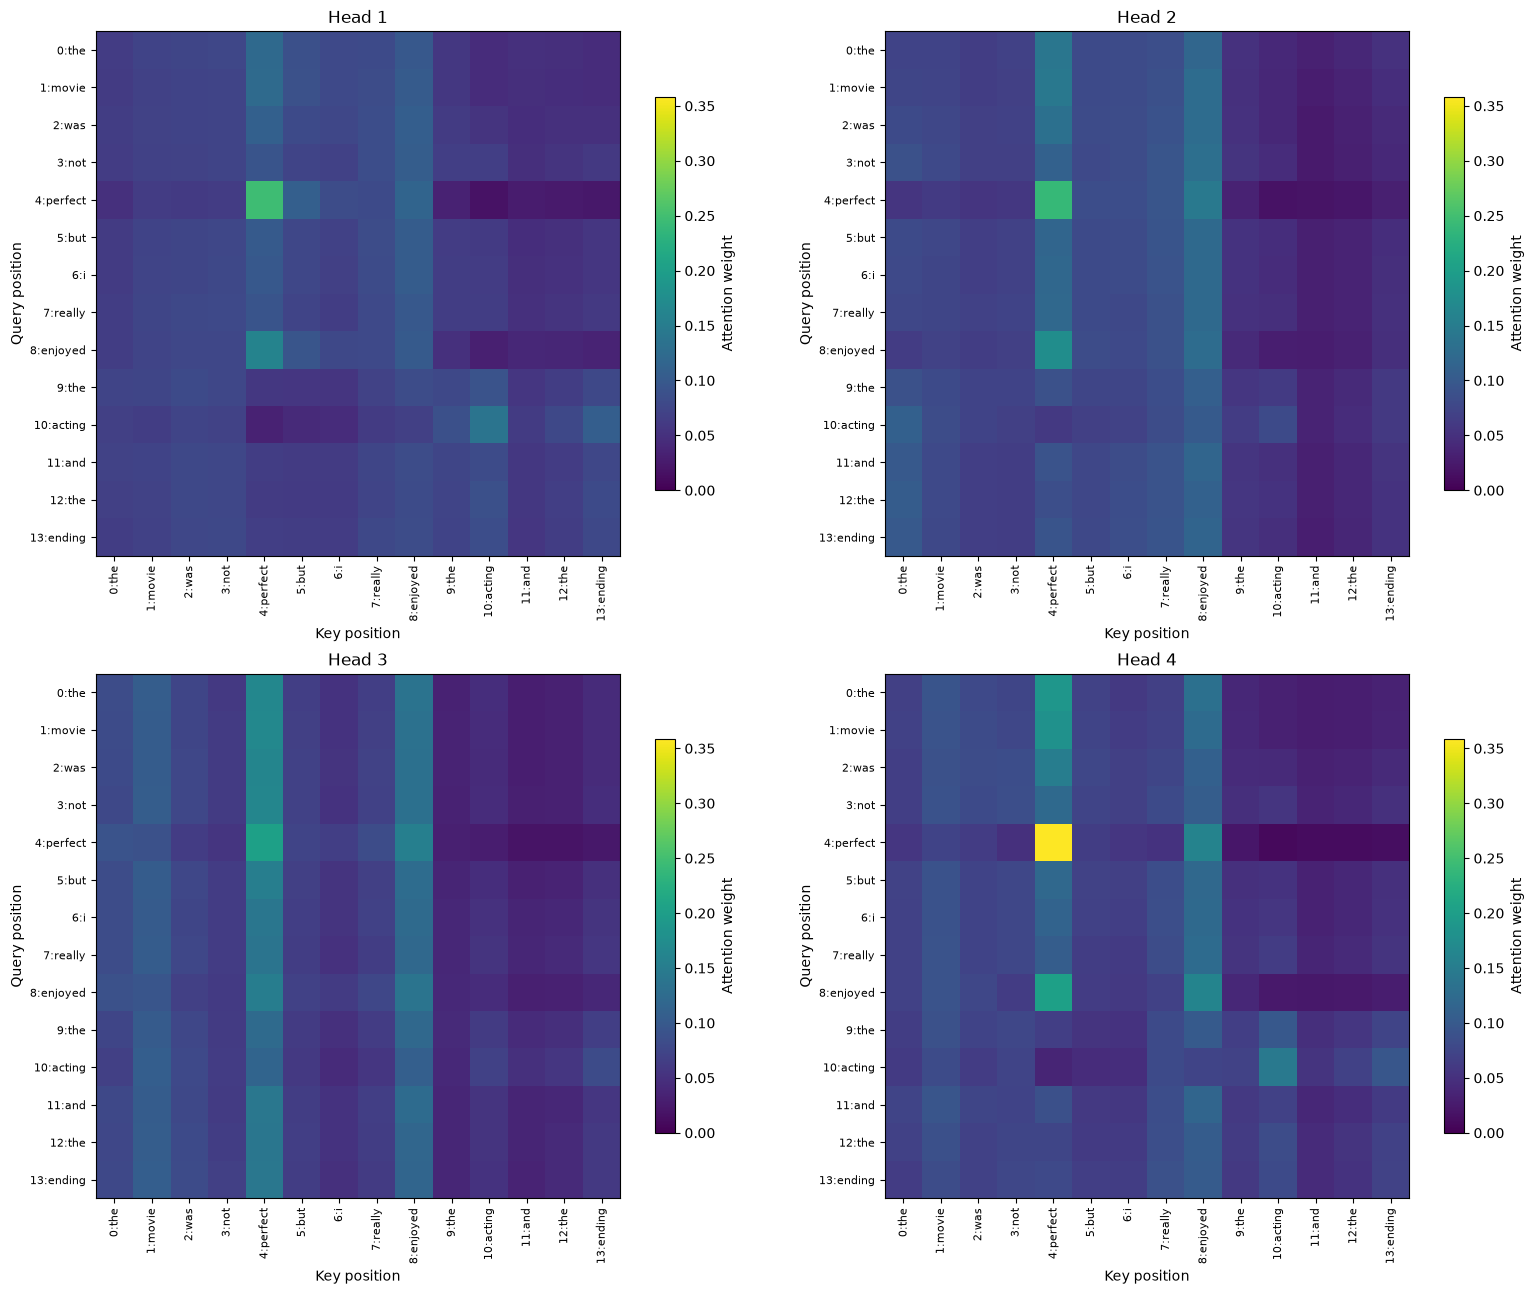

,experiment,run_id,head_a,head_b,cosine_similarity,mean_absolute_difference
0,3,transformer_h4_len128_mean,1,2,0.972739,0.015021
1,3,transformer_h4_len128_mean,1,3,0.947249,0.019875
2,3,transformer_h4_len128_mean,1,4,0.976255,0.012579
3,3,transformer_h4_len128_mean,2,3,0.972695,0.014100
4,3,transformer_h4_len128_mean,2,4,0.974043,0.013257
5,3,transformer_h4_len128_mean,3,4,0.964398,0.013779


In [9]:
# 20. Experiment 3: visualize moi head cua Transformer 4 heads da huan luyen.
attention_text = 'The movie was not perfect but I really enjoyed the acting and the ending.'
attention_tokens = tokenize(attention_text)[:min(48, CFG['max_length'])]
attention_ids = torch.tensor([[vocab.get(t, UNK) for t in attention_tokens]], device=DEVICE)
attention_model = load_run(baseline_run)
with torch.inference_mode():
    attention_logits, attention_weights = attention_model(attention_ids, return_attention=True)
weights = attention_weights[0].cpu().numpy()
np.savez(ARTIFACTS / 'attention_heads.npz', attention=weights,
         tokens=np.asarray(attention_tokens), token_ids=attention_ids.cpu().numpy())
fig, axes = plt.subplots(2, 2, figsize=(16, 13))
shared_vmax = max(float(weights.max()), 1e-8)
for head, ax in enumerate(axes.flat):
    image = ax.imshow(weights[head], vmin=0, vmax=shared_vmax, cmap='viridis')
    positions = np.arange(len(attention_tokens))
    labels = [f'{i}:{token}' for i, token in enumerate(attention_tokens)]
    ax.set_xticks(positions, labels, rotation=90, fontsize=8)
    ax.set_yticks(positions, labels, fontsize=8)
    ax.set(xlabel='Key position', ylabel='Query position', title=f'Head {head+1}')
    fig.colorbar(image, ax=ax, shrink=.75, label='Attention weight')
fig.tight_layout()
fig.savefig(OUT / 'attention_heads.png', dpi=160)
plt.show()
plt.close(fig)

diversity_rows = []
for first in range(weights.shape[0]):
    for second in range(first+1, weights.shape[0]):
        a, b = weights[first].ravel(), weights[second].ravel()
        diversity_rows.append(dict(experiment=3, run_id=baseline_run['record']['run_id'],
                                   head_a=first+1, head_b=second+1,
                                   cosine_similarity=float(np.dot(a,b)/(np.linalg.norm(a)*np.linalg.norm(b))),
                                   mean_absolute_difference=float(np.abs(a-b).mean())))
diversity = pd.DataFrame(diversity_rows)
diversity.to_csv(ARTIFACTS / 'experiment3_head_diversity.csv', index=False)
RESULT_ROWS.extend(diversity_rows)
save_results()
display(diversity)
del attention_model, attention_logits, attention_weights
if DEVICE.type == 'cuda':
    torch.cuda.empty_cache()


In [10]:
# 21. Experiment 4: LSTM va Transformer, cung controls va train/val/test split.
lstm_run = train_run(model_spec(architecture='LSTM', n_heads=1, max_length=CFG['max_length']))
comparison_rows = [record_experiment(4, run) for run in (lstm_run, baseline_run)]
comparison = pd.DataFrame(comparison_rows)
comparison.to_csv(ARTIFACTS / 'experiment4_lstm_transformer.csv', index=False)
display(comparison[['model', 'parameters', 'training_time_seconds',
                    'accuracy', 'precision', 'recall', 'f1']])


lstm_h1_len128_mean: epoch 1/6 train_loss=0.5663 val_loss=0.4171


lstm_h1_len128_mean: epoch 2/6 train_loss=0.3218 val_loss=0.4139


lstm_h1_len128_mean: epoch 3/6 train_loss=0.2226 val_loss=0.4876


lstm_h1_len128_mean: epoch 4/6 train_loss=0.1514 val_loss=0.5036


lstm_h1_len128_mean: epoch 5/6 train_loss=0.1257 val_loss=0.6655


lstm_h1_len128_mean: epoch 6/6 train_loss=0.0843 val_loss=0.6576


,model,parameters,training_time_seconds,accuracy,precision,recall,f1
0,LSTM,2692482,84.495259,0.822614,0.835141,0.806543,0.820593
1,Transformer,2758658,45.611914,0.837730,0.845257,0.829184,0.837143


In [11]:
# 22. Experiment 5: max_length=32,64,128,256; fixed padding de do dung T cua attention.
length_rows, retention_rows = [], []
for max_length in (32, 64, 128, 256):
    run = train_run(model_spec(n_heads=4, max_length=max_length))
    for split, frame in frames.items():
        original_tokens = frame.tokens.map(len).to_numpy()
        retained_tokens = np.minimum(original_tokens, max_length)
        retention_rows.append(dict(max_length=max_length, split=split,
                                   original_tokens=int(original_tokens.sum()),
                                   tokens_retained=int(retained_tokens.sum()),
                                   retained_fraction=float(retained_tokens.sum()/original_tokens.sum()),
                                   truncated_reviews=int((original_tokens > max_length).sum())))
    train_retention = next(r for r in retention_rows
                           if r['max_length']==max_length and r['split']=='train')
    elements = CFG['batch_size'] * 4 * max_length**2
    length_rows.append(record_experiment(
        5, run, tokens_retained=train_retention['tokens_retained'],
        retained_fraction=train_retention['retained_fraction'],
        attention_elements_per_full_batch=elements,
        attention_scores_theoretical_mib=elements*torch.tensor([],dtype=torch.float32).element_size()/1024**2,
        attention_memory_scope='one float32 scores tensor, one layer, one full batch'))
length_results = pd.DataFrame(length_rows)
length_results.to_csv(ARTIFACTS / 'experiment5_lengths.csv', index=False)
pd.DataFrame(retention_rows).to_csv(ARTIFACTS / 'tokens_retained.csv', index=False)
display(length_results[['max_length', 'tokens_retained', 'retained_fraction',
                        'attention_scores_theoretical_mib', 'training_cuda_peak_allocated_mib',
                        'training_time_seconds', 'f1']])


transformer_h4_len32_mean: epoch 1/6 train_loss=0.6430 val_loss=0.5250


transformer_h4_len32_mean: epoch 2/6 train_loss=0.4519 val_loss=0.5174


transformer_h4_len32_mean: epoch 3/6 train_loss=0.3626 val_loss=0.5878


transformer_h4_len32_mean: epoch 4/6 train_loss=0.3019 val_loss=0.5713


transformer_h4_len32_mean: epoch 5/6 train_loss=0.2414 val_loss=0.6319


transformer_h4_len32_mean: epoch 6/6 train_loss=0.1899 val_loss=0.7833


... (9 outputs left out)

transformer_h4_len256_mean: epoch 4/6 train_loss=0.1364 val_loss=0.4129


transformer_h4_len256_mean: epoch 5/6 train_loss=0.0983 val_loss=0.4270


transformer_h4_len256_mean: epoch 6/6 train_loss=0.0637 val_loss=0.5410


,max_length,tokens_retained,retained_fraction,attention_scores_theoretical_mib,training_cuda_peak_allocated_mib,training_time_seconds,f1
0,32,637067,0.136657,1.0,123.392578,44.731963,0.755750
1,64,1260750,0.270443,4.0,155.114746,55.223848,0.786284
2,128,2378237,0.510154,16.0,231.498047,45.611914,0.837143
3,256,3567279,0.765215,64.0,526.556641,91.470033,0.866672


In [12]:
# 25. Experiment 6: mean vs CLS; max_length tinh ca token CLS.
# CLS chiem mot vi tri trong cung sequence budget.
cls_run = train_run(model_spec(n_heads=4, max_length=CFG['max_length'], pooling='cls'))
pooling_rows = [record_experiment(6, run,
                    special_tokens=int(run['spec']['pooling']=='cls'),
                    content_token_budget=run['spec']['max_length']-int(run['spec']['pooling']=='cls'))
                for run in (baseline_run, cls_run)]
pooling_results = pd.DataFrame(pooling_rows)
pooling_results.to_csv(ARTIFACTS / 'experiment6_pooling.csv', index=False)
display(pooling_results[['pooling', 'content_token_budget', 'accuracy', 'f1', 'training_time_seconds']])


transformer_h4_len128_cls: epoch 1/6 train_loss=0.5955 val_loss=0.3706


transformer_h4_len128_cls: epoch 2/6 train_loss=0.3272 val_loss=0.3692


transformer_h4_len128_cls: epoch 3/6 train_loss=0.2438 val_loss=0.4353


transformer_h4_len128_cls: epoch 4/6 train_loss=0.1812 val_loss=0.4020


transformer_h4_len128_cls: epoch 5/6 train_loss=0.1290 val_loss=0.4860


transformer_h4_len128_cls: epoch 6/6 train_loss=0.0937 val_loss=0.6130


,pooling,content_token_budget,accuracy,f1,training_time_seconds
0,mean,128,0.837730,0.837143,45.611914
1,cls,127,0.833637,0.846122,39.084353


In [13]:
# 23. Application: short, long, negation, contrast, ambiguous sentiment.
application_model = load_run(baseline_run)
APPLICATION_CASES = [
    ('short', 'I really enjoyed this movie.'),
    ('long', ('The story follows a family through many changes and the actors give '
              'convincing performances in every scene. ')*30 + 'I enjoyed this movie.'),
    ('negation', 'I did not enjoy this movie. It was not good at all.'),
    ('contrast', 'The opening was slow and dull, but the ending was excellent and I loved it.'),
    ('ambiguous', 'The movie was okay, neither particularly good nor particularly bad.'),
]

def predict_text(text, model=application_model, spec=baseline_run['spec']):
    tokens = tokenize(text)
    ids = encode_tokens(tokens, spec['max_length'], spec['pooling'])
    model.eval()
    with torch.inference_mode():
        logits = model(torch.tensor([ids], dtype=torch.long, device=DEVICE),
                       torch.tensor([len(ids)], dtype=torch.long))
        probabilities = logits.softmax(-1)[0].cpu().numpy()
    predicted = int(probabilities.argmax())
    budget = spec['max_length'] - int(spec['pooling']=='cls')
    return dict(text=text, prediction=['Negative', 'Positive'][predicted],
                probability=float(probabilities[predicted]),
                positive_probability=float(probabilities[1]),
                original_tokens=len(tokens), retained_tokens=min(len(tokens), budget),
                truncated=len(tokens)>budget)

application_results = pd.DataFrame([dict(category=category, **predict_text(text))
                                    for category, text in APPLICATION_CASES])
application_results.to_csv(ARTIFACTS / 'application_predictions.csv', index=False)
display(application_results[['category', 'prediction', 'probability', 'positive_probability',
                             'original_tokens', 'retained_tokens', 'truncated']])
prediction = predict_text('I really enjoyed this movie.')
print(prediction['prediction'])
print(f"Probability: {prediction['probability']:.4f}")


,category,prediction,probability,positive_probability,original_tokens,retained_tokens,truncated
0,short,Positive,0.999564,0.999564,5,5,False
1,long,Positive,0.895781,0.895781,514,128,True
2,negation,Negative,0.708180,0.291820,12,12,False
3,contrast,Negative,0.964220,0.035780,15,15,False
4,ambiguous,Negative,0.997173,0.002827,10,10,False


Positive
Probability: 0.9996


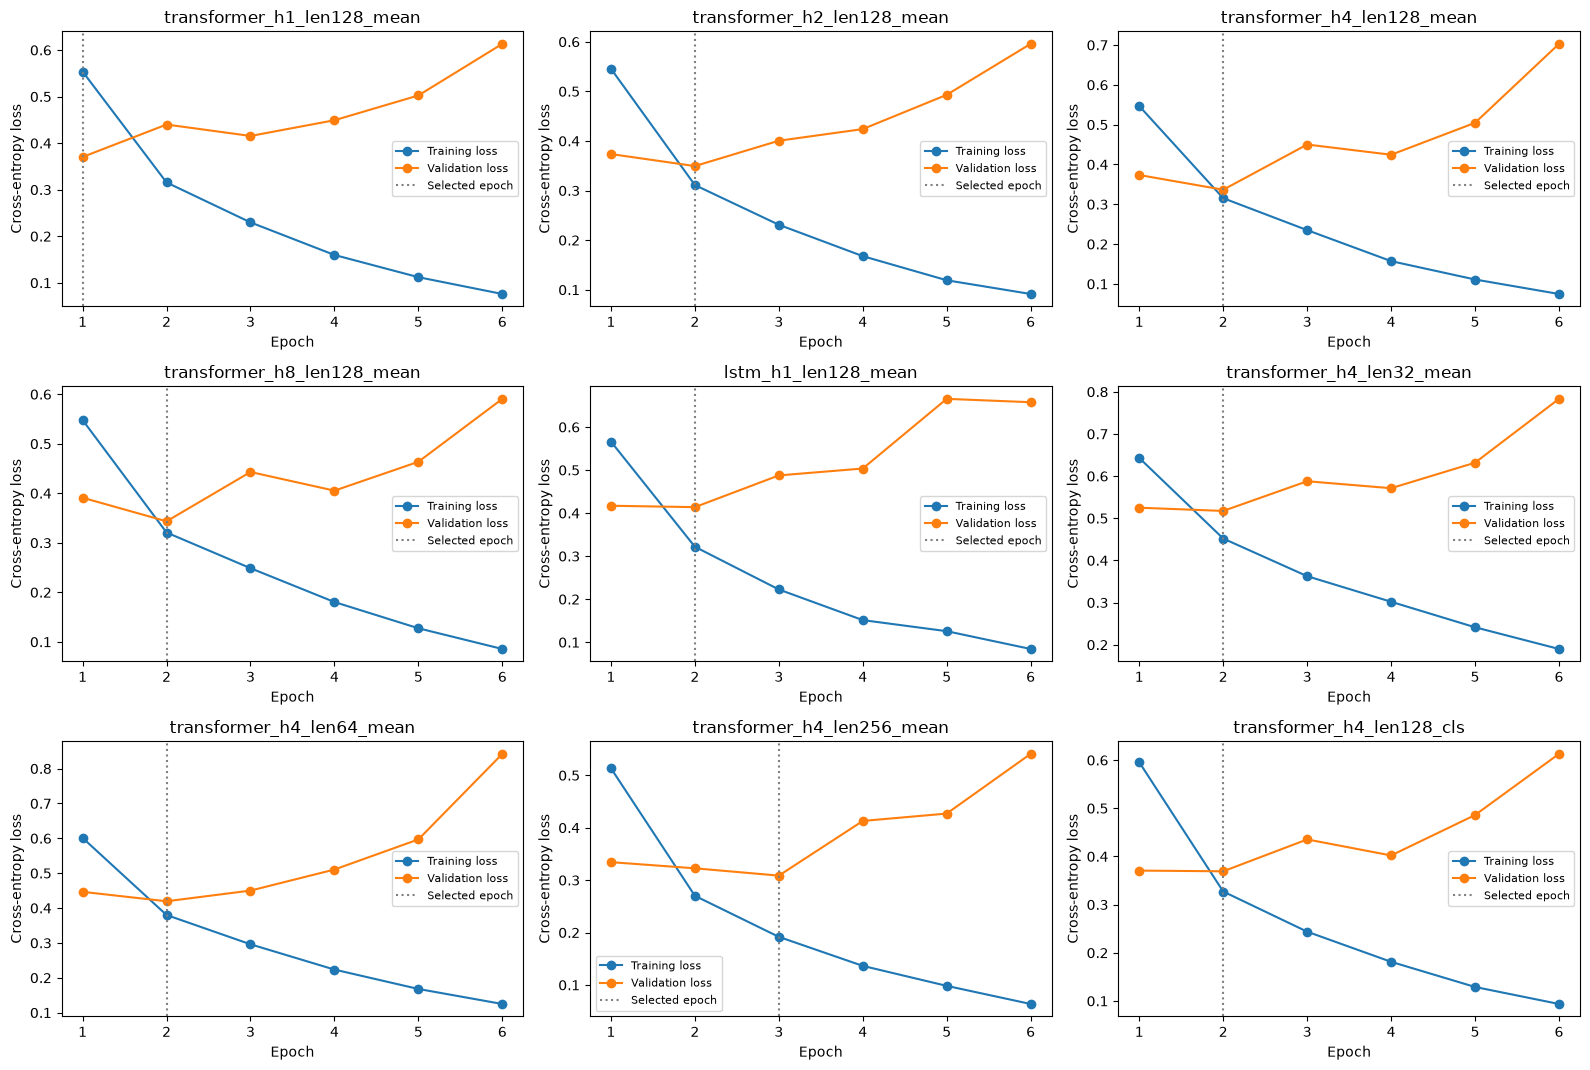

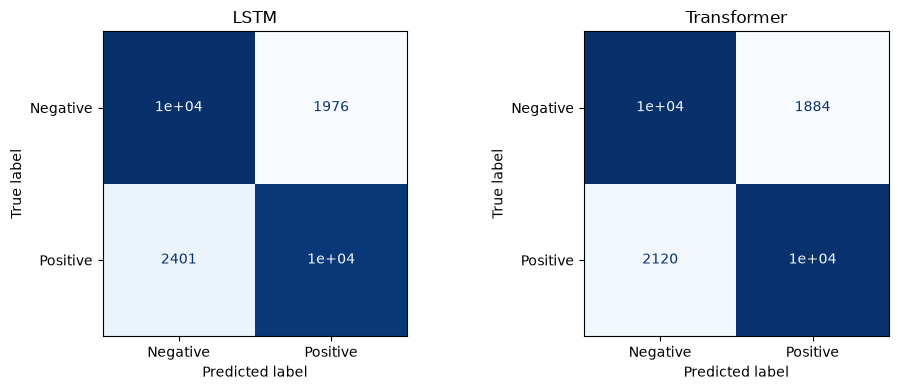

Results: C:\Users\Acer\Documents\NLP\lab07\results.csv
Figures: C:\Users\Acer\Documents\NLP\lab07
Checkpoints / per-run CSV: C:\Users\Acer\Documents\NLP\lab07\outputs


In [ ]:
# 29. Learning curves va confusion matrix tu cac lan chay that.
histories = pd.concat([pd.DataFrame(run['history']) for run in RUNS.values()], ignore_index=True)
histories.to_csv(ARTIFACTS / 'learning_history.csv', index=False)
columns = 3
rows = math.ceil(len(RUNS)/columns)
fig, axes = plt.subplots(rows, columns, figsize=(16, 3.6*rows), squeeze=False)
for ax, (run_id, run) in zip(axes.flat, RUNS.items()):
    history = pd.DataFrame(run['history'])
    ax.plot(history.epoch, history.train_loss, marker='o', label='Training loss')
    ax.plot(history.epoch, history.validation_loss, marker='o', label='Validation loss')
    ax.axvline(run['record']['selected_epoch'], color='gray', linestyle=':', label='Selected epoch')
    ax.set(title=run_id, xlabel='Epoch', ylabel='Cross-entropy loss')
    ax.set_xticks(history.epoch)
    ax.legend(fontsize=8)
for ax in list(axes.flat)[len(RUNS):]:
    ax.set_visible(False)
fig.tight_layout()
fig.savefig(OUT / 'learning_curves.png', dpi=160)
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, run in zip(axes, (lstm_run, baseline_run)):
    matrix = confusion_matrix(run['labels'], run['probabilities'].argmax(1), labels=[0, 1])
    ConfusionMatrixDisplay(matrix, display_labels=['Negative', 'Positive']).plot(
        ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(run['record']['model'])
fig.tight_layout()
fig.savefig(OUT / 'confusion_matrix.png', dpi=160)
plt.show()
plt.close(fig)
results = save_results()



In [15]:
# Kiem tra hoan tat cac experiment va cac artifact do code sinh ra.
assert set(results.experiment.astype(int)) == {1, 2, 3, 4, 5, 6}
assert set(head_results.heads) == {1, 2, 4, 8}
assert head_results.d_model.eq(128).all()
assert set(length_results.max_length) == {32, 64, 128, 256}
assert set(comparison.model) == {'LSTM', 'Transformer'}
assert set(pooling_results.pooling) == {'mean', 'cls'}
assert application_results.probability.between(0, 1).all()
assert application_results.positive_probability.between(0, 1).all()
assert len(application_results) >= 5
for run in RUNS.values():
    assert np.isfinite(run['probabilities']).all()
    assert np.allclose(run['probabilities'].sum(1), 1, atol=1e-6)
    assert Path(run['checkpoint']).is_file()
for name in ('results.csv', 'positional_encoding.png', 'attention_heads.png',
             'learning_curves.png', 'confusion_matrix.png'):
    assert (OUT / name).is_file(), name
print(f'OK: {len(RUNS)} training runs; Experiments 1-6; mode={MODE}.')


OK: 9 training runs; Experiments 1-6; mode=full.
